# Customer Churn: Exploratory Data Analysis

Exploratory analysis of the cleaned IBM Telco customer churn dataset.

**Input:** `../dataset/telco_churn_clean.csv`, produced by `data_cleaning.py`.
**Run from:** the `python/` folder (`jupyter notebook`).

Every finding here is an association in historical data and does not establish causation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

CHURN_COLOR, RETAINED_COLOR = "#C0392B", "#5D6D7E"
TENURE_ORDER = ["0-12 months", "13-24 months", "25-48 months", "49-60 months", "61+ months"]
CONTRACT_ORDER = ["Month-to-month", "One year", "Two year"]

In [4]:
df = pd.read_csv("dataset/telco_churn_clean.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,churn_flag,tenure_group
0,7590-VHVEG,Female,0,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0,0-12 months
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,"1,889.50",No,0,25-48 months
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,0-12 months
3,7795-CFOCW,Male,0,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer,42.30,"1,840.75",No,0,25-48 months
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,0-12 months


## 1. Dataset structure

In [5]:
print("Rows, columns:", df.shape)
df.dtypes

Rows, columns: (7043, 23)


customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
churn_flag            int64
tenure_group            str
dtype: object

In [6]:
# Data quality re-check on the cleaned file
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().any().any() else "none")
print("\nDuplicate rows:", df.duplicated().sum())
print("Unique customer IDs:", df["customerID"].nunique(), "of", len(df))

Missing values per column:
none

Duplicate rows: 0
Unique customer IDs: 7043 of 7043


## 2. Churn distribution

,customers,share_pct
Churn,,
No,5174,73.46
Yes,1869,26.54


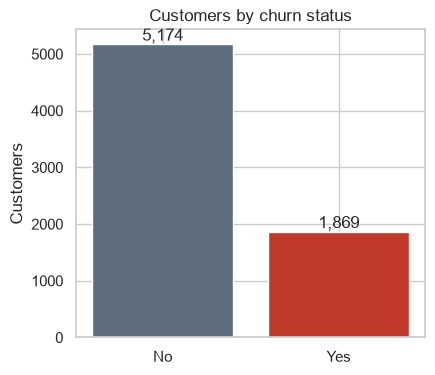

In [7]:
counts = df["Churn"].value_counts()
share = df["Churn"].value_counts(normalize=True).mul(100).round(2)
display(pd.DataFrame({"customers": counts, "share_pct": share}))

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.bar(counts.index, counts.values, color=[RETAINED_COLOR if i == "No" else CHURN_COLOR for i in counts.index])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
ax.set_title("Customers by churn status")
ax.set_ylabel("Customers")
plt.show()

## 3. Numerical variables

In [8]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
display(df[num_cols].describe().T)

display(df.groupby("Churn")[num_cols].agg(["mean", "median"]).round(2))

,count,mean,std,min,25%,50%,75%,max
tenure,"7,043.00",32.37,24.56,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,"7,043.00",64.76,30.09,18.25,35.50,70.35,89.85,118.75
TotalCharges,"7,043.00","2,279.73","2,266.79",0.00,398.55,"1,394.55","3,786.60","8,684.80"


tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57  38.00          61.27  64.43     2,549.91 1,679.52
Yes    17.98  10.00          74.44  79.65     1,531.80   703.55

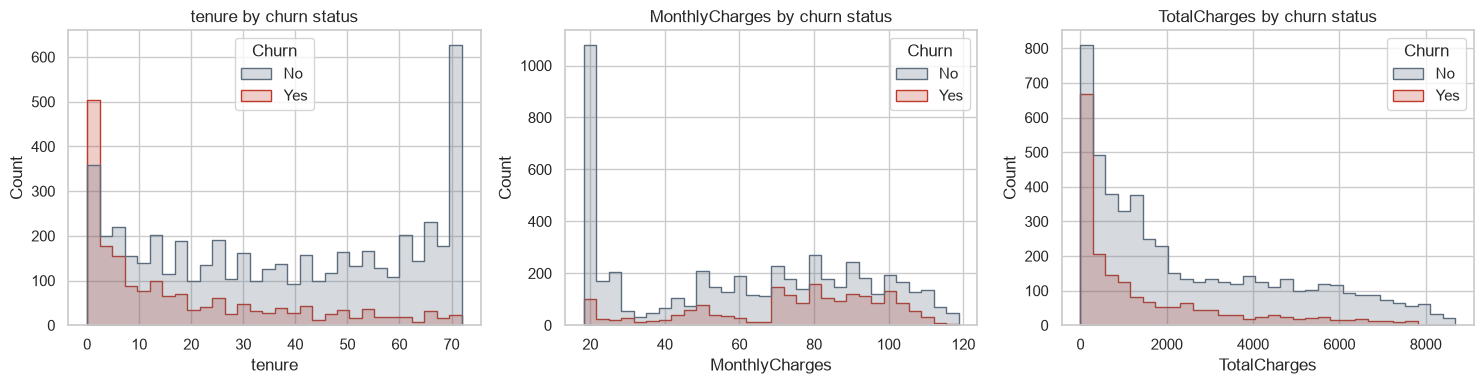

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue="Churn", bins=30, element="step", stat="count",
                 palette={"No": RETAINED_COLOR, "Yes": CHURN_COLOR}, ax=ax)
    ax.set_title(f"{col} by churn status")
plt.tight_layout()
plt.show()

## 4. Categorical variables: churn rate by segment

The helper below returns customers, churned customers, churn rate, and the monthly charges of churned customers (a historical segment measure, not a forecast) for any column.

In [10]:
def churn_by(col, order=None):
    g = (df.assign(churn_charges=df["MonthlyCharges"] * df["churn_flag"])
           .groupby(col)
           .agg(customers=("customerID", "count"),
                churned=("churn_flag", "sum"),
                churn_rate_pct=("churn_flag", lambda s: round(100 * s.mean(), 2)),
                churn_monthly_charges=("churn_charges", "sum")))
    g["share_of_churn_charges_pct"] = (100 * g["churn_monthly_charges"] / g["churn_monthly_charges"].sum()).round(2)
    g["small_group"] = np.where(g["customers"] < 30, "yes", "")
    if order:
        g = g.reindex(order)
    else:
        g = g.sort_values("churn_rate_pct", ascending=False)
    return g

overall_rate = 100 * df["churn_flag"].mean()

def plot_churn_by(col, order=None, ax=None, rotate=0):
    g = churn_by(col, order)
    ax = ax or plt.gca()
    ax.bar(g.index.astype(str), g["churn_rate_pct"], color=CHURN_COLOR)
    ax.axhline(overall_rate, color="black", linestyle="--", linewidth=1, label=f"Overall {overall_rate:.1f}%")
    for i, (rate, n) in enumerate(zip(g["churn_rate_pct"], g["customers"])):
        ax.text(i, rate, f"{rate:.1f}%\n(n={n:,})", ha="center", va="bottom", fontsize=8)
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate (%)")
    ax.set_ylim(0, g["churn_rate_pct"].max() * 1.25)
    ax.tick_params(axis="x", rotation=rotate)
    ax.legend()

for col, order in [("Contract", CONTRACT_ORDER), ("tenure_group", TENURE_ORDER),
                   ("PaymentMethod", None), ("InternetService", None)]:
    print(f"--- {col} ---")
    display(churn_by(col, order))

--- Contract ---


,customers,churned,churn_rate_pct,churn_monthly_charges,share_of_churn_charges_pct,small_group
Contract,,,,,,
Month-to-month,3875,1655,42.71,"120,847.10",86.86,
One year,1473,166,11.27,"14,118.45",10.15,
Two year,1695,48,2.83,"4,165.30",2.99,


--- tenure_group ---


,customers,churned,churn_rate_pct,churn_monthly_charges,share_of_churn_charges_pct,small_group
tenure_group,,,,,,
0-12 months,2186,1037,47.44,"68,954.25",49.56,
13-24 months,1024,294,28.71,"23,081.65",16.59,
25-48 months,1594,325,20.39,"27,462.50",19.74,
49-60 months,832,120,14.42,"10,581.90",7.61,
61+ months,1407,93,6.61,"9,050.55",6.51,


--- PaymentMethod ---


,customers,churned,churn_rate_pct,churn_monthly_charges,share_of_churn_charges_pct,small_group
PaymentMethod,,,,,,
Electronic check,2365,1071,45.29,"84,288.75",60.58,
Mailed check,1612,308,19.11,"16,803.60",12.08,
Bank transfer,1544,258,16.71,"20,091.90",14.44,
Credit card,1522,232,15.24,"17,946.60",12.90,


--- InternetService ---


,customers,churned,churn_rate_pct,churn_monthly_charges,share_of_churn_charges_pct,small_group
InternetService,,,,,,
Fiber optic,3096,1297,41.89,"114,300.05",82.15,
DSL,2421,459,18.96,"22,529.20",16.19,
No,1526,113,7.40,"2,301.60",1.65,


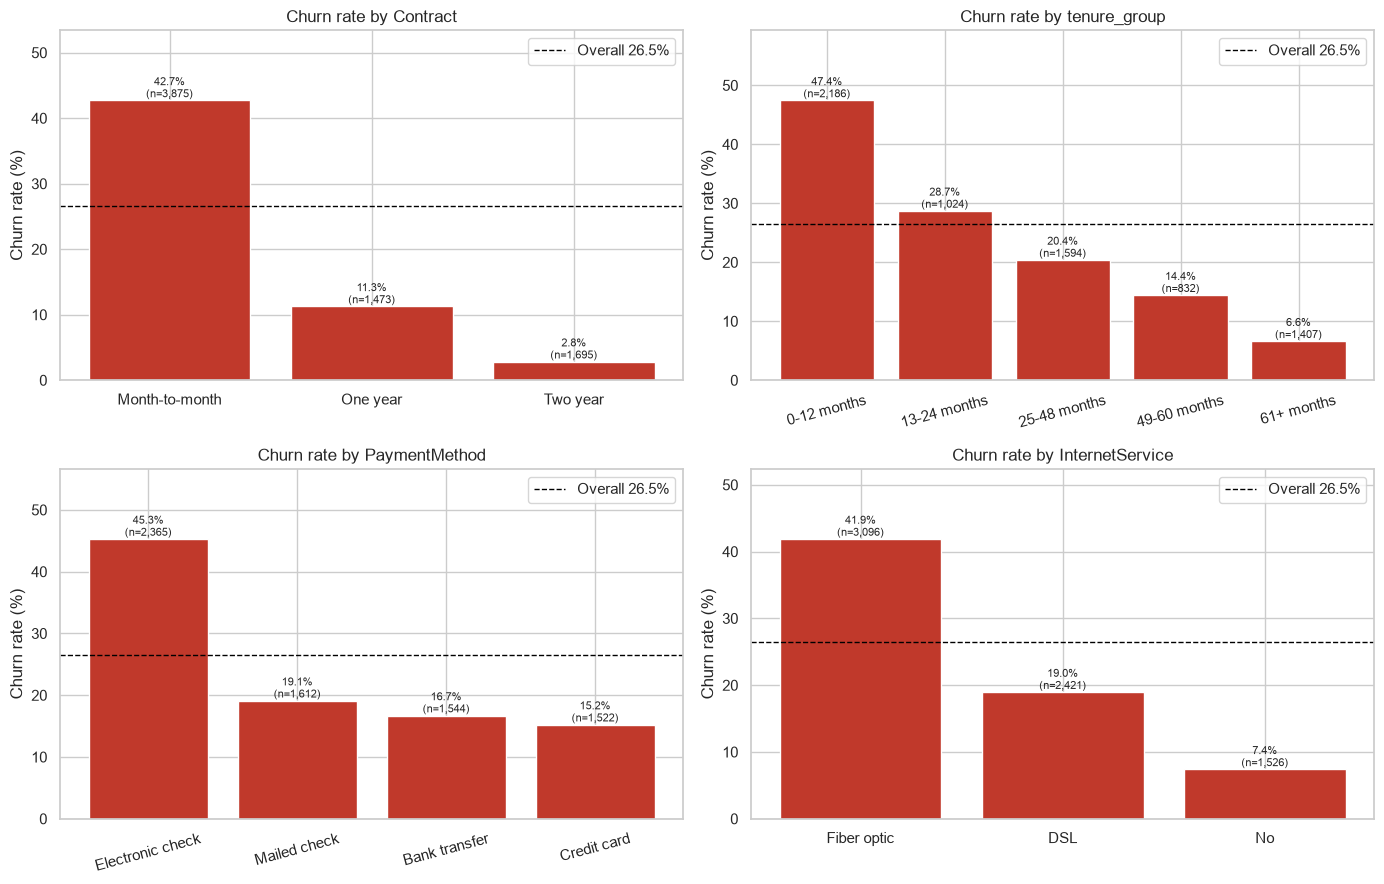

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plot_churn_by("Contract", CONTRACT_ORDER, axes[0, 0])
plot_churn_by("tenure_group", TENURE_ORDER, axes[0, 1], rotate=15)
plot_churn_by("PaymentMethod", None, axes[1, 0], rotate=15)
plot_churn_by("InternetService", None, axes[1, 1])
plt.tight_layout()
plt.show()

In [12]:
# Demographics and add-on services
demo_cols = ["gender", "SeniorCitizen", "Partner", "Dependents", "PaperlessBilling"]
service_cols = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

summary_rows = []
for col in demo_cols + service_cols:
    for value, row in churn_by(col).iterrows():
        summary_rows.append({"field": col, "value": value, "customers": row["customers"],
                             "churn_rate_pct": row["churn_rate_pct"]})
pd.DataFrame(summary_rows)

,field,value,customers,churn_rate_pct
0,gender,Female,3488,26.92
1,gender,Male,3555,26.16
2,SeniorCitizen,1,1142,41.68
3,SeniorCitizen,0,5901,23.61
4,Partner,No,3641,32.96
5,Partner,Yes,3402,19.66
6,Dependents,No,4933,31.28
7,Dependents,Yes,2110,15.45
8,PaperlessBilling,Yes,4171,33.57
9,PaperlessBilling,No,2872,16.33


Add-on service fields mix two groups of customers: those who do not have the service and those who have no internet at all (both are "No" after cleaning). Compare these fields within customers who have internet service when judging them.

In [13]:
with_internet = df[df["InternetService"] != "No"]
rows = []
for col in ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]:
    r = with_internet.groupby(col)["churn_flag"].agg(["count", "mean"])
    for value, vals in r.iterrows():
        rows.append({"service": col, "has_service": value, "customers": int(vals["count"]),
                     "churn_rate_pct": round(100 * vals["mean"], 2)})
pd.DataFrame(rows)

,service,has_service,customers,churn_rate_pct
0,OnlineSecurity,No,3498,41.77
1,OnlineSecurity,Yes,2019,14.61
2,OnlineBackup,No,3088,39.93
3,OnlineBackup,Yes,2429,21.53
4,DeviceProtection,No,3095,39.13
5,DeviceProtection,Yes,2422,22.50
6,TechSupport,No,3473,41.64
7,TechSupport,Yes,2044,15.17
8,StreamingTV,No,2810,33.52
9,StreamingTV,Yes,2707,30.07


## 5. Combinations of factors

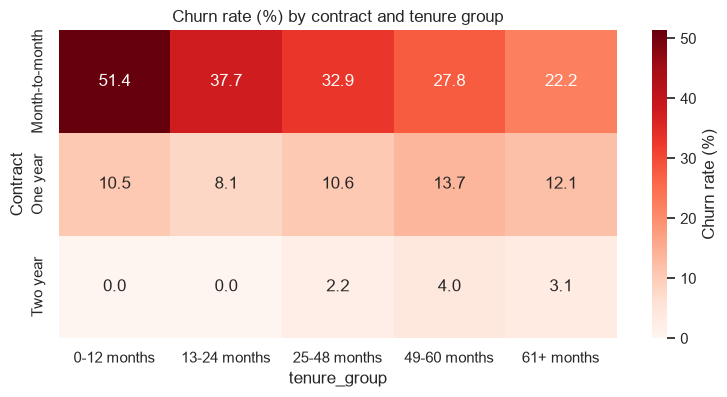

Customers per cell:


tenure_group,0-12 months,13-24 months,25-48 months,49-60 months,61+ months
Contract,,,,,
Month-to-month,1994,737,802,234,108
One year,124,197,518,321,313
Two year,68,90,274,277,986


In [14]:
pivot = (df.pivot_table(index="Contract", columns="tenure_group", values="churn_flag", aggfunc="mean")
           .reindex(index=CONTRACT_ORDER, columns=TENURE_ORDER).mul(100))
sizes = (df.pivot_table(index="Contract", columns="tenure_group", values="customerID", aggfunc="count")
           .reindex(index=CONTRACT_ORDER, columns=TENURE_ORDER))

plt.figure(figsize=(9, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Churn rate (%)"})
plt.title("Churn rate (%) by contract and tenure group")
plt.show()
print("Customers per cell:")
display(sizes)

In [15]:
# Do month-to-month, fiber optic and electronic check customers overlap, and do the traits stack?
df["is_m2m"] = df["Contract"] == "Month-to-month"
df["is_fiber"] = df["InternetService"] == "Fiber optic"
df["is_echeck"] = df["PaymentMethod"] == "Electronic check"
df["risk_traits"] = df[["is_m2m", "is_fiber", "is_echeck"]].sum(axis=1)

by_traits = (df.groupby("risk_traits")
               .agg(customers=("customerID", "count"), churned=("churn_flag", "sum"),
                    churn_rate_pct=("churn_flag", lambda s: round(100 * s.mean(), 2))))
by_traits["share_of_all_churned_pct"] = (100 * by_traits["churned"] / by_traits["churned"].sum()).round(2)
display(by_traits)

combined = df[df["risk_traits"] == 3]
print(f"Customers with all three traits: {len(combined):,} ({100 * len(combined) / len(df):.1f}% of customers)")
print(f"Their churn rate: {100 * combined['churn_flag'].mean():.1f}% vs {100 * df.loc[df['risk_traits'] < 3, 'churn_flag'].mean():.1f}% for everyone else")
print(f"Share of all churned customers: {100 * combined['churn_flag'].sum() / df['churn_flag'].sum():.1f}%")

,customers,churned,churn_rate_pct,share_of_all_churned_pct
risk_traits,,,,
0,1973,62,3.14,3.32
1,2111,380,18.00,20.33
2,1652,638,38.62,34.14
3,1307,789,60.37,42.22


Customers with all three traits: 1,307 (18.6% of customers)
Their churn rate: 60.4% vs 18.8% for everyone else
Share of all churned customers: 42.2%


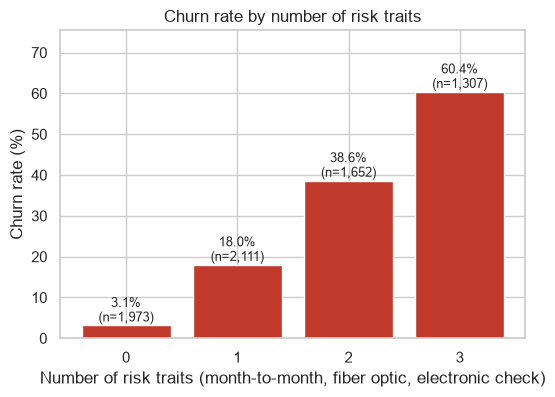

In [16]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(by_traits.index.astype(str), by_traits["churn_rate_pct"], color=CHURN_COLOR)
for i, (rate, n) in enumerate(zip(by_traits["churn_rate_pct"], by_traits["customers"])):
    ax.text(i, rate, f"{rate:.1f}%\n(n={n:,})", ha="center", va="bottom", fontsize=9)
ax.set_xlabel("Number of risk traits (month-to-month, fiber optic, electronic check)")
ax.set_ylabel("Churn rate (%)")
ax.set_title("Churn rate by number of risk traits")
ax.set_ylim(0, by_traits["churn_rate_pct"].max() * 1.25)
plt.show()

## 6. Relationships between numeric variables

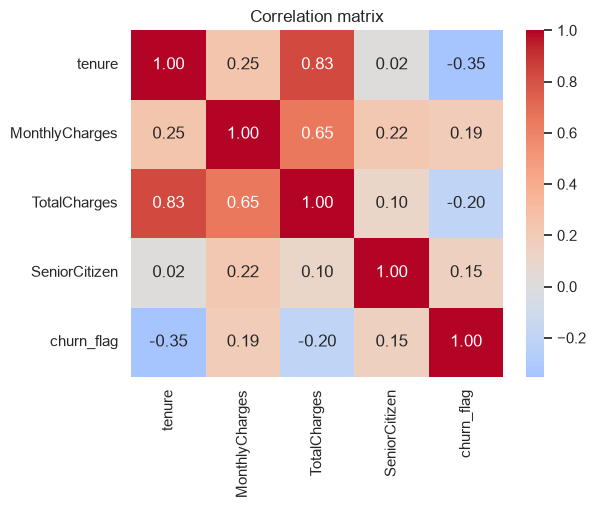

In [17]:
corr_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "churn_flag"]
corr = df[corr_cols].corr()
plt.figure(figsize=(6, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

`TotalCharges` is largely `tenure x MonthlyCharges`, so it moves with tenure. Treat it as derived and avoid reading it as an independent driver. Correlations measure linear association only and are not evidence of cause.

## 7. Reconcile with SQL reference values

In [18]:
# Reference values from sql/data_validation.sql (query 8), run on the same data.
sql_reference = {
    "total_customers": 7043, "churned_customers": 1869, "active_customers": 5174,
    "churn_rate_pct": 26.54, "retention_rate_pct": 73.46, "avg_tenure_months": 32.37,
    "avg_monthly_charges": 64.76, "monthly_charges_associated_with_churn": 139130.85,
    "avg_revenue_per_customer": 64.76,
}

python_values = {
    "total_customers": df["customerID"].nunique(),
    "churned_customers": int(df["churn_flag"].sum()),
    "active_customers": int((df["churn_flag"] == 0).sum()),
    "churn_rate_pct": round(100 * df["churn_flag"].mean(), 2),
    "retention_rate_pct": round(100 * (1 - df["churn_flag"].mean()), 2),
    "avg_tenure_months": round(df["tenure"].mean(), 2),
    "avg_monthly_charges": round(df["MonthlyCharges"].mean(), 2),
    "monthly_charges_associated_with_churn": round(df.loc[df["churn_flag"] == 1, "MonthlyCharges"].sum(), 2),
    "avg_revenue_per_customer": round(df["MonthlyCharges"].sum() / len(df), 2),
}

check = pd.DataFrame({"sql": pd.Series(sql_reference), "python": pd.Series(python_values)})
check["difference"] = (check["python"] - check["sql"]).round(2)
check["status"] = np.where(check["difference"].abs() <= 0.01, "match", "investigate")
check

,sql,python,difference,status
total_customers,"7,043.00","7,043.00",0.00,match
churned_customers,"1,869.00","1,869.00",0.00,match
active_customers,"5,174.00","5,174.00",0.00,match
churn_rate_pct,26.54,26.54,0.00,match
retention_rate_pct,73.46,73.46,0.00,match
avg_tenure_months,32.37,32.37,0.00,match
avg_monthly_charges,64.76,64.76,0.00,match
monthly_charges_associated_with_churn,"139,130.85","139,130.85",0.00,match
avg_revenue_per_customer,64.76,64.76,0.00,match


## 8. Summary, assumptions and limitations

### Key findings from the 7,043-customer dataset

The cleaned IBM Telco Customer Churn dataset contains **7,043 customers**. There are **1,869 churned customers** and **5,174 retained customers**, giving an overall churn rate of **26.54%** and retention rate of **73.46%**. Average customer tenure is **32.37 months** and average monthly charges are **64.76**. The monthly charges associated with customers who churned total **139,130.85**; this is a historical monthly-charge measure, not a forecast.

#### Customer and contract patterns

- **Contract type is strongly associated with churn:** month-to-month customers have a **42.7%** churn rate, compared with **11.3%** for one-year contracts and **2.8%** for two-year contracts.
- **Churn is highest among newer customers:** the rate is **47.4%** for 0–12 months, then falls across the tenure groups to **6.6%** for customers with 61+ months of tenure.
- **Payment method:** electronic-check customers have the highest churn rate (**45.3%**), followed by mailed check (**19.1%**), bank transfer (**16.7%**) and credit card (**15.2%**).
- **Internet service:** churn is **41.9%** for fiber-optic customers, **19.0%** for DSL customers and **7.4%** for customers without internet service.
- **Demographic/household segments:** senior citizens have a **41.7%** churn rate versus **23.6%** for non-senior customers. Customers without a partner have **33.0%** churn versus **19.7%** for customers with a partner; customers without dependents have **31.3%** churn versus **15.5%** for customers with dependents. Churn is similar by gender (**26.9%** female; **26.2%** male).

#### Tenure, charges and service patterns

- Average tenure is **37.57 months** among retained customers and **17.98 months** among churned customers.
- Average monthly charges are **61.27** for retained customers and **74.44** for churned customers. Churned customers therefore have higher average monthly charges in this dataset.
- Among customers with internet service, churn is higher for customers without online security (**41.8%**) and tech support (**41.6%**) than for customers with those services (**14.6%** and **15.2%**, respectively). The same direction appears for online backup (**39.9%** without vs **21.5%** with) and device protection (**39.1%** without vs **22.5%** with). Streaming TV and streaming movies show smaller differences.

#### Combined risk traits

The combined risk-trait definition counts the presence of each of these three attributes: **month-to-month contract**, **fiber-optic internet**, and **electronic-check payment**.

| Number of traits | Customers | Churn rate |
|---:|---:|---:|
| 0 | 1,973 | 3.1% |
| 1 | 2,111 | 18.0% |
| 2 | 1,652 | 38.6% |
| 3 | 1,307 | 60.4% |

The group with all three traits contains **1,307 customers**. **789** of them churned, representing **42.2% of all churned customers**. The churn rate increases with the number of these traits present. This is a descriptive association, not evidence that any one trait causes churn.

#### Interpretation of the contract–tenure matrix

For month-to-month customers, churn decreases across tenure bands: **51.4%** at 0–12 months, **37.7%** at 13–24 months, **32.9%** at 25–48 months, **27.8%** at 49–60 months and **22.2%** at 61+ months. Contract and tenure should be interpreted together because the pattern differs across contract types.

### Assumptions

- Churn status is accurate and final; the dataset has no dates, so we cannot tell when customers churned.
- Blank `TotalCharges` for customers with tenure 0 were set to 0 during cleaning.
- The currency of the charge fields is not stated in the source.
- The risk-trait count is a descriptive flag: one point each for month-to-month contract, fiber-optic internet and electronic-check payment.

### Limitations

- Findings are associations, not causes, and historical patterns may not describe current customers.
- Segments overlap, so per-dimension shares of churn must not be added together.
- Small groups (the `small_group` column) produce unstable rates.
- Monthly charges associated with churn represent the churned customers' recorded monthly charges; they should not be interpreted as realized lifetime loss or a revenue forecast.
